# Projet DVF : étape 4, dérive temporelle (tendance par zone, walk-forward, pondération)

**Constat de l'étape 3** : le modèle sous-estime 2025 de 4 % en moyenne et de **9 % dans le Pays de Gex**, dont les prix montent régulièrement (+8 % en 3 ans) alors que le reste de l'Ain est stable. Un arbre ne sait pas extrapoler une tendance.

**Trois remèdes testés**
1. **Pondération par ancienneté** : les ventes récentes pèsent plus (demi-vie de 12 mois).
2. **Tendance par zone** : on mesure, sur le passé seulement, la dérive des résidus par zone (Pays de Gex ou autre, éventuellement × type de bien), puis on l'extrapole.
3. **Walk-forward** : on réentraîne chaque trimestre avec les ventes déjà connues. Le paramètre `lag` simule le délai de disponibilité des données (le DVF est publié environ 2 fois par an, donc un délai réaliste est de 3 à 9 mois).

**Protocole anti-contamination** : chaque scénario est évalué sur un **backtest 2024** (entraînement sur le passé jusqu'à fin 2023), qui sert à **choisir**, puis sur le **test 2025**, regardé une seule fois pour le scénario retenu. Même variables que l'étape 3 (sans l'indice régional). Modèle : LightGBM (3 graines).

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings, os
import lightgbm as lgb
from sklearn.model_selection import KFold
warnings.filterwarnings('ignore')
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 60)

SEED, SEEDS = 42, (0, 1, 2)
DATA = 'data'
HALF_LIFE = 12          # mois : demi-vie des poids de pondération
TREND_WIN = 24          # mois : fenêtre sur laquelle la tendance est mesurée
FINAL_SCENARIO = None   # None = choix automatique sur le backtest 2024

## 1. Données et variables

In [2]:
df = pd.read_parquet(f'{DATA}/dvf_features_etape3.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

BASE_NUM = ['surface_bati','log_surface','pieces','surface_terrain','log_terrain','nb_dependances',
            'a_dependance','surface_carrez','carrez_dispo','mois','mois_sin','mois_cos']
GEO = ['lat','lon','dist_geneve_km','dist_lyon_km','dist_bourg_km']
PROFIL = ['population','log_population'] + [c for c in df.columns if c.startswith('fil_')]
CAT = ['type_local','commune']
FEATS_NUM = BASE_NUM + GEO + PROFIL
print(df.shape, '| variables :', len(FEATS_NUM) + len(CAT))

LGB_PARAMS = dict(objective='regression', learning_rate=0.03, num_leaves=31, min_child_samples=20,
                  subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0,
                  cat_smooth=20, cat_l2=10, min_data_per_group=10, verbose=-1)

def X_of(d, cats):
    X = d[FEATS_NUM + CAT].copy()
    for c in CAT: X[c] = pd.Categorical(X[c], categories=cats[c])
    return X

def tindex(dates):                                  # mois écoulés depuis 2022-01-01 (continu)
    return ((dates.dt.year - 2022) * 12 + dates.dt.month - 1 + (dates.dt.day - 1) / 30.4).values

def group_key(d, groups):
    if not groups: return pd.Series('all', index=d.index)
    return d[groups].astype(str).agg('|'.join, axis=1)

def metrics(y_true, y_pred):
    e = y_pred - y_true; ape = np.abs(e) / y_true
    return {'MedAPE %': np.median(ape)*100, 'MAPE %': ape.mean()*100, '±20 %': (ape <= .2).mean()*100,
            'MAE': np.abs(e).mean(), 'biais médian %': np.median(e / y_true)*100}

# nombre d'arbres : arrêt anticipé UNE fois (entraînement ≤ 2023, validation 2024)
tr0, va0 = df[df.annee <= 2023], df[df.annee == 2024]
cats0 = {c: tr0[c].astype('category').cat.categories for c in CAT}
es = lgb.LGBMRegressor(n_estimators=5000, random_state=SEED, **LGB_PARAMS)
es.fit(X_of(tr0, cats0), tr0['y'], eval_set=[(X_of(va0, cats0), va0['y'])],
       callbacks=[lgb.early_stopping(100, verbose=False)])
N_TREES = max(int(es.best_iteration_), 50)
print('Nombre d\'arbres fixé pour tous les scénarios :', N_TREES)

(30125, 39) | variables : 26
Nombre d'arbres fixé pour tous les scénarios : 318


## 2. Moteur : ajustement, tendance par zone, fenêtres walk-forward
**Tendance par zone.** Sur la fenêtre d'entraînement, on calcule des résidus *hors échantillon* (validation croisée 5 blocs) du modèle sans variable temporelle. Ces résidus mesurent, par zone, de combien les prix d'un mois s'écartent du niveau moyen appris. On ajuste une droite sur les `TREND_WIN` derniers mois, par zone, puis on l'extrapole à la date de la vente à prédire. `shrink` atténue la pente (1 = pente entière).

In [3]:
def trend_corr(win, Xw, yw, w, tgt, groups, shrink):
    oof = np.zeros(len(win))
    for a, b in KFold(5, shuffle=True, random_state=SEED).split(Xw):
        m = lgb.LGBMRegressor(n_estimators=N_TREES, random_state=SEED, **LGB_PARAMS)
        m.fit(Xw.iloc[a], yw[a], sample_weight=None if w is None else w[a])
        oof[b] = m.predict(Xw.iloc[b])
    r = yw - oof
    tw, tt = tindex(win['date']), tindex(tgt['date'])
    sel = tw >= tw.max() - TREND_WIN
    kw, kt = group_key(win, groups).values, group_key(tgt, groups).values

    def ajuste(mask):
        t, rr = tw[mask], r[mask]
        slope = np.polyfit(t, rr, 1)[0]
        return lambda x: rr.mean() + shrink * slope * (x - t.mean())

    f_glob = ajuste(sel)
    corr = np.zeros(len(tgt))
    for g in np.unique(kt):
        mask = sel & (kw == g)
        f = ajuste(mask) if mask.sum() >= 40 else f_glob
        corr[kt == g] = f(tt[kt == g])
    return corr

def fit_predict(win, tgt, use_w=False, trend=None, shrink=1.0):
    cats = {c: win[c].astype('category').cat.categories for c in CAT}
    Xw, Xt, yw = X_of(win, cats), X_of(tgt, cats), win['y'].values
    w = None
    if use_w:
        age = (win['date'].max() - win['date']).dt.days.values / 30.44
        w = 0.5 ** (age / HALF_LIFE)
    lp = np.mean([lgb.LGBMRegressor(n_estimators=N_TREES, random_state=s, **LGB_PARAMS)
                  .fit(Xw, yw, sample_weight=w).predict(Xt) for s in SEEDS], axis=0)
    if trend is not None:
        lp = lp + trend_corr(win, Xw, yw, w, tgt, trend, shrink)
    return lp

def predict_year(year, sc):
    tgt_all = df[df.annee == year]
    out = pd.Series(np.nan, index=tgt_all.index)
    if sc['mode'] == 'static':
        windows = [(pd.Timestamp(year, 1, 1), tgt_all.index)]
    else:
        windows = []
        for q in range(4):
            qs = pd.Timestamp(year, 3 * q + 1, 1)
            idx = tgt_all[(tgt_all.date >= qs) & (tgt_all.date < qs + pd.DateOffset(months=3))].index
            windows.append((qs - pd.DateOffset(months=sc.get('lag', 0)), idx))
    for cutoff, idx in windows:
        if len(idx) == 0: continue
        win = df[df.date < cutoff]
        out[idx] = np.exp(fit_predict(win, df.loc[idx], sc.get('w', False), sc.get('trend'), sc.get('shrink', 1.0)))
    return out.values

## 3. Scénarios
`A` reproduit exactement l'étape 3 (jeu « coordonnées + profil », sans l'indice). Le `lag` est en mois : le walk-forward avec `lag = 0` suppose que toutes les ventes du trimestre précédent sont déjà connues (optimiste).

In [4]:
SC = {
 'A · statique (étape 3)':                     dict(mode='static'),
 'B · statique + pondération':                 dict(mode='static', w=True),
 'C · statique + tendance zone':               dict(mode='static', trend=['pays_de_gex']),
 'D · statique + tendance zone×type':          dict(mode='static', trend=['pays_de_gex', 'type_local']),
 'E · statique + tendance zone (pente ×0,5)':  dict(mode='static', trend=['pays_de_gex'], shrink=0.5),
 'F · walk-forward lag 0':                     dict(mode='wf', lag=0),
 'G · walk-forward lag 3':                     dict(mode='wf', lag=3),
 'H · walk-forward lag 6':                     dict(mode='wf', lag=6),
 'I · walk-forward lag 3 + pondération':       dict(mode='wf', lag=3, w=True),
 'J · walk-forward lag 3 + tendance zone':     dict(mode='wf', lag=3, trend=['pays_de_gex']),
 'K · walk-forward lag 3 + pond. + tendance':  dict(mode='wf', lag=3, w=True, trend=['pays_de_gex']),
 'L · walk-forward lag 6 + pond. + tendance':  dict(mode='wf', lag=6, w=True, trend=['pays_de_gex']),
}
P = {}    # P[(scénario, année)] = prédictions en €/m²
for name, sc in SC.items():
    for year in (2024, 2025):
        P[(name, year)] = predict_year(year, sc)
    print(f'{name:45s} fait')

A · statique (étape 3)                        fait
B · statique + pondération                    fait
C · statique + tendance zone                  fait
D · statique + tendance zone×type             fait
E · statique + tendance zone (pente ×0,5)     fait
F · walk-forward lag 0                        fait
G · walk-forward lag 3                        fait
H · walk-forward lag 6                        fait
I · walk-forward lag 3 + pondération          fait
J · walk-forward lag 3 + tendance zone        fait
K · walk-forward lag 3 + pond. + tendance     fait
L · walk-forward lag 6 + pond. + tendance     fait


## 4. Résultats
- **2024 (backtest)** sert à choisir. **2025 (test)** est la mesure finale.
- `Δ MedAPE` : écart avec le scénario A en points de % (négatif = mieux), intervalle de confiance bootstrap apparié à 95 % (✓ = exclut 0).

In [5]:
y24, y25 = df.loc[df.annee == 2024, 'prix_m2'].values, df.loc[df.annee == 2025, 'prix_m2'].values
gex25 = df.loc[df.annee == 2025, 'pays_de_gex'].values == 1

def delta_ci(p_ref, p_new, t, n=500):
    a, b = np.abs(p_ref - t) / t, np.abs(p_new - t) / t
    rng = np.random.default_rng(SEED); d = []
    for _ in range(n):
        i = rng.integers(0, len(t), len(t)); d.append(np.median(b[i]) - np.median(a[i]))
    return np.percentile(np.array(d) * 100, [2.5, 97.5])

ref = 'A · statique (étape 3)'
rows = []
for name in SC:
    m24, m25 = metrics(y24, P[(name, 2024)]), metrics(y25, P[(name, 2025)])
    p = P[(name, 2025)]
    lo, hi = delta_ci(P[(ref, 2025)], p, y25) if name != ref else (0, 0)
    rows.append({'scénario': name,
                 'MedAPE 2024 (choix)': m24['MedAPE %'], 'biais 2024': m24['biais médian %'],
                 'MedAPE 2025 (test)': m25['MedAPE %'], 'Δ MedAPE': m25['MedAPE %'] - metrics(y25, P[(ref, 2025)])['MedAPE %'],
                 'IC95 Δ': f'[{lo:+.2f} ; {hi:+.2f}]', 'sig.': '✓' if (lo > 0 or hi < 0) else '',
                 'MAPE %': m25['MAPE %'], '±20 %': m25['±20 %'], 'MAE': m25['MAE'],
                 'biais 2025': m25['biais médian %'],
                 'biais Gex': np.median((p[gex25] - y25[gex25]) / y25[gex25]) * 100,
                 'biais hors Gex': np.median((p[~gex25] - y25[~gex25]) / y25[~gex25]) * 100})
RES = pd.DataFrame(rows).set_index('scénario')
display(RES.round(2))

CHOIX = FINAL_SCENARIO or RES['MedAPE 2024 (choix)'].idxmin()
print('\nScénario retenu (meilleur sur le backtest 2024) :', CHOIX)

,MedAPE 2024 (choix),biais 2024,MedAPE 2025 (test),Δ MedAPE,IC95 Δ,sig.,MAPE %,±20 %,MAE,biais 2025,biais Gex,biais hors Gex
scénario,,,,,,,,,,,,
A · statique (étape 3),16.58,-0.91,16.12,0.00,[+0.00 ; +0.00],,24.01,59.95,565.02,-4.21,-8.68,-2.92
B · statique + pondération,16.60,-1.20,16.39,0.27,[+0.04 ; +0.53],✓,24.00,59.60,566.37,-4.70,-7.59,-3.82
C · statique + tendance zone,16.49,-1.04,17.11,0.99,[+0.68 ; +1.32],✓,23.63,57.56,577.31,-7.90,-4.90,-8.94
D · statique + tendance zone×type,16.48,-1.11,17.19,1.07,[+0.76 ; +1.42],✓,23.64,57.69,577.70,-7.76,-4.00,-8.95
"E · statique + tendance zone (pente ×0,5)",16.47,-1.05,16.62,0.50,[+0.26 ; +0.70],✓,23.65,58.98,568.43,-6.44,-6.41,-6.46
F · walk-forward lag 0,16.56,-1.10,16.13,0.01,[-0.17 ; +0.16],,23.90,60.67,561.42,-4.45,-8.28,-3.17
G · walk-forward lag 3,16.58,-0.92,16.15,0.03,[-0.14 ; +0.20],,23.97,60.22,563.89,-4.22,-8.60,-2.96
H · walk-forward lag 6,16.55,-0.95,16.20,0.08,[-0.10 ; +0.21],,24.01,60.08,565.18,-4.18,-8.62,-2.89
I · walk-forward lag 3 + pondération,16.62,-1.20,16.27,0.15,[-0.12 ; +0.39],,23.94,59.81,565.27,-4.73,-7.74,-3.83



Scénario retenu (meilleur sur le backtest 2024) : E · statique + tendance zone (pente ×0,5)


### Biais par mois en 2025 : scénario A contre scénario retenu

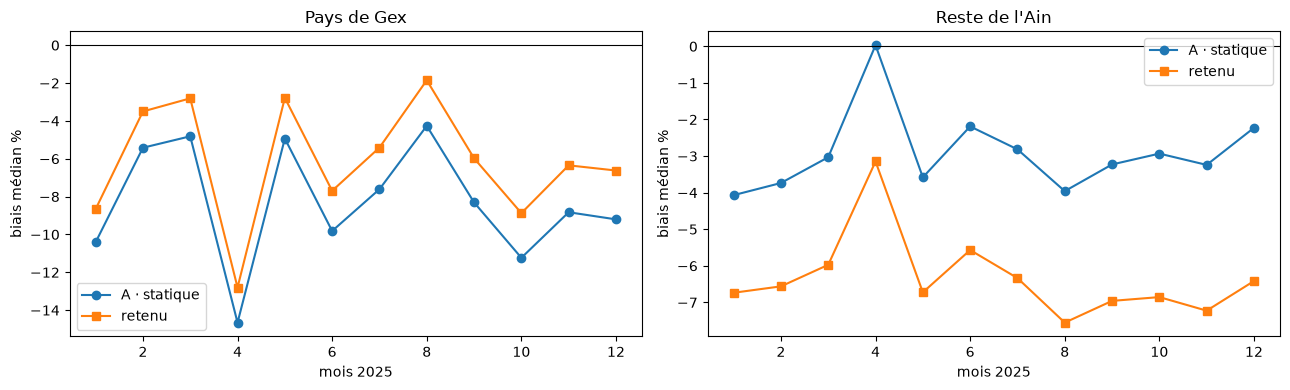

In [6]:
t25 = df[df.annee == 2025].copy()
t25['bA'] = (P[(ref, 2025)] - t25['prix_m2']) / t25['prix_m2'] * 100
t25['bC'] = (P[(CHOIX, 2025)] - t25['prix_m2']) / t25['prix_m2'] * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for k, (titre, m) in enumerate([('Pays de Gex', t25.pays_de_gex == 1), ('Reste de l\'Ain', t25.pays_de_gex == 0)]):
    g = t25[m].groupby('mois')[['bA', 'bC']].median()
    ax[k].plot(g.index, g['bA'], 'o-', label='A · statique'); ax[k].plot(g.index, g['bC'], 's-', label='retenu')
    ax[k].axhline(0, color='k', lw=.8); ax[k].set_title(titre); ax[k].set_xlabel('mois 2025'); ax[k].set_ylabel('biais médian %'); ax[k].legend()
plt.tight_layout(); plt.show()

## 5. Détail du scénario retenu (test 2025)

In [7]:
t25['pred'] = P[(CHOIX, 2025)]
t25['ape'] = np.abs(t25.pred - t25.prix_m2) / t25.prix_m2 * 100
t25['ape_A'] = np.abs(P[(ref, 2025)] - t25.prix_m2) / t25.prix_m2 * 100
t25['tranche_prix'] = pd.cut(t25.prix_m2, [0, 1000, 1500, 2000, 3000, 4000, 12000])
for col in ['pays_de_gex', 'type_local', 'tranche_prix']:
    g = t25.groupby(col, observed=True)
    print(f'--- par {col}')
    display(pd.DataFrame({'n': g.size(), 'MedAPE A': g['ape_A'].median(), 'MedAPE retenu': g['ape'].median(),
                          'biais A': g['bA'].median(), 'biais retenu': g['bC'].median()}).round(1))

--- par pays_de_gex


,n,MedAPE A,MedAPE retenu,biais A,biais retenu
pays_de_gex,,,,,
0,6306,16.8,17.7,-2.9,-6.5
1,1342,13.7,12.8,-8.7,-6.4


--- par type_local


,n,MedAPE A,MedAPE retenu,biais A,biais retenu
type_local,,,,,
Appartement,2768,15.5,15.7,-5.7,-6.7
Maison,4880,16.6,17.3,-3.4,-6.2


--- par tranche_prix


,n,MedAPE A,MedAPE retenu,biais A,biais retenu
tranche_prix,,,,,
"(0, 1000]",252,98.9,92.5,98.9,92.5
"(1000, 1500]",753,36.6,32.2,36.6,31.9
"(1500, 2000]",1199,15.1,14.7,8.2,4.4
"(2000, 3000]",2696,14.1,15.2,-6.7,-10.0
"(3000, 4000]",1321,15.5,17.7,-11.2,-14.1
"(4000, 12000]",1427,14.5,13.7,-13.8,-12.7


## 6. Intervalles de prédiction à 80 % (Mondrian)
Les écarts de calibration viennent du **backtest 2024 du même scénario**, jamais du test 2025.

In [8]:
ALPHA = 0.20
d24, d25 = df[df.annee == 2024], df[df.annee == 2025]
r24 = np.abs(d24['y'].values - np.log(P[(CHOIX, 2024)]))
def qconf(r):
    n = len(r); return np.quantile(r, min(1, np.ceil((n + 1) * (1 - ALPHA)) / n))
q_glob = qconf(r24)
g24 = (d24['type_local'] + '_' + d24['pays_de_gex'].astype(str)).values
g25 = (d25['type_local'] + '_' + d25['pays_de_gex'].astype(str)).values
q_grp = {g: (qconf(r24[g24 == g]) if (g24 == g).sum() >= 30 else q_glob) for g in np.unique(g24)}
centre = np.log(P[(CHOIX, 2025)])
qt = np.array([q_grp.get(g, q_glob) for g in g25])
IV = {'globale': (np.exp(centre - q_glob), np.exp(centre + q_glob)),
      'Mondrian (type × Gex)': (np.exp(centre - qt), np.exp(centre + qt))}
rows = []
for k, (lo, hi) in IV.items():
    ok = (y25 >= lo) & (y25 <= hi)
    rows.append({'méthode': k, 'couverture %': ok.mean()*100, 'largeur relative médiane %': np.median((hi - lo) / np.exp(centre))*100,
                 'couv. Appartement': ok[d25.type_local.values == 'Appartement'].mean()*100,
                 'couv. Maison': ok[d25.type_local.values == 'Maison'].mean()*100,
                 'couv. Pays de Gex': ok[gex25].mean()*100, 'couv. hors Gex': ok[~gex25].mean()*100})
print('Objectif :', (1 - ALPHA) * 100, '%'); display(pd.DataFrame(rows).set_index('méthode').round(1))

Objectif : 80.0 %


,couverture %,largeur relative médiane %,couv. Appartement,couv. Maison,couv. Pays de Gex,couv. hors Gex
méthode,,,,,,
globale,80.5,70.7,84.8,78.1,92.8,77.9
Mondrian (type × Gex),80.9,79.7,80.3,81.2,84.2,80.2


## 7. Sauvegarde

In [9]:
RES.to_csv(f'{DATA}/etape4_scenarios.csv')
out = d25[['date', 'commune', 'type_local', 'pays_de_gex', 'surface_bati', 'prix_m2']].copy()
out['pred_A'] = P[(ref, 2025)]; out['pred_retenu'] = P[(CHOIX, 2025)]
out['lo80'], out['hi80'] = IV['Mondrian (type × Gex)']
out.to_csv(f'{DATA}/etape4_predictions_test.csv', index=False)
print('Sauvegardé : etape4_scenarios.csv, etape4_predictions_test.csv')

Sauvegardé : etape4_scenarios.csv, etape4_predictions_test.csv


## À retenir pour le rapport
1. Comparer A à chaque remède : gain, intervalle de confiance, et effet sur le **biais du Pays de Gex**.
2. Le choix du scénario repose sur le backtest 2024, pas sur le test 2025 : c'est la bonne pratique, mentionne-la.
3. Le walk-forward suppose un délai de disponibilité des données (`lag`) : précise celui que tu retiens et pourquoi.
4. Limites : tendance linéaire extrapolée (elle peut se retourner), zone définie par une liste de codes postaux, tendance mesurée sur peu d'années.